# TP2 - Parte 1: Dataset y preprocesamiento

Esta notebook documenta el análisis y la preparación del **70 Dog Breeds Image Dataset**, utilizado para desarrollar el sistema de detección y clasificación de razas de perros, que incluye:

- Análisis exploratorio del dataset (EDA).
- Detección de errores y filtrado de imágenes.
- Construcción de un conjunto independiente de evaluación.
- Definición del pipeline de preprocesamiento.
- Aplicación de técnicas de *data augmentation*.
- Definición y validación de los conjuntos de entrenamiento, validación y prueba (*train, validation y test*).

Los resultados de esta notebook se utilizarán posteriormente para entrenar y comparar los modelos de clasificación, y en las etapas de búsqueda por similitud y detección de perros.

## Equipo
- Alumno 1 : Cicoria, Ignacio
- Alumno 2 : Ricci, Guillermo

## 1. Clonar el repositorio


In [ ]:
# URL del fork
REPO_URL = "https://github.com/guillericci/tuia-dog-recognition-app.git"

# Clonar la rama
!git clone --branch feature/tp2-razas-perros $REPO_URL proyecto

# Entrar al repositorio
%cd proyecto


fatal: destination path 'proyecto' already exists and is not an empty directory.
/content/proyecto


## 2. Instalar dependencias

Colab ya incluye torch, torchvision, opencv, numpy, scikit-learn y matplotlib;
solo se instala lo que falta.

In [ ]:
!pip install -q pydantic-settings python-dotenv kagglehub albumentations onnxruntime

## 3. Configuración del entorno

En Colab no hay PostgreSQL, por lo que se desactiva pgvector y se usa la base vectorial JSON.
La configuración se define por variables de entorno **antes** de importar `lib`.

In [ ]:
import os
import sys
import random
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import hashlib


os.environ["USE_PGVECTOR"] = "false"
# Ajustá acá cualquier otra variable (IMAGE_SIZE, EMBEDDING_DIM, paths, etc.)

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from lib.config import settings

import torch
print("dataset_path:", settings.dataset_path)
print("GPU disponible:", torch.cuda.is_available())

dataset_path: data/dataset
GPU disponible: True


In [ ]:
# `settings` ya se importó en la celda de configuración del entorno.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATASET_ROOT = settings.dataset_path
EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

#DATASET = Path(settings.dataset_path)          # data/dataset
SPLITS = ["train", "valid", "test"]            # nombres reales del dataset de Kaggle

OUT_DIR = Path("data/splits")                  # acá van los CSV que reutiliza 2-train
OUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 4. Descargar el dataset

In [ ]:
!python scripts/download_dataset.py
!ls data/dataset

Descargando gpiosenka/70-dog-breedsimage-data-set ...
Using Colab cache for faster access to the '70-dog-breedsimage-data-set' dataset.
Dataset disponible en /content/proyecto/data/dataset
dogs.csv  test	train  valid


## 5. Descripción del dataset


El dataset [70 Dog Breeds](https://https://www.kaggle.com/datasets/gpiosenka/70-dog-breedsimage-data-set?) contiene fotografias de perros organizadas por raza, donde cada carpeta representa una clase distinta.

Todas las imagenes estan redimensionadas a 224 x 244 pixeles en formato JPG.

 El creador indica que se eliminaron duplicados para generar los conjuntos de entrenamiento, validacion y prueba correctamente.

**Estructura del dataset**

```
dataset/
│
├── train/
│   ├── beagle/
│   ├── boxer/
│   ├── chihuahua/
│   └── ...
│
├── valid/
│   ├── beagle/
│   ├── boxer/
│   └── ...
│
└── test/
    ├── beagle/
    ├── boxer/
    └── ...
```



Razas por split: {'test': 70, 'train': 70, 'valid': 70}
Imágenes por split: {'train': 7946, 'valid': 700, 'test': 700}
Archivos corruptos: 0
Formatos: {'.jpg': 9346}
Modos de color: {'RGB': 9346}
Resoluciones (ancho x alto): {(224, 224): 9346}

Estadísticas de imágenes por raza:
split   train  valid  test
mean    111.9    9.9   9.9
median  111.0   10.0  10.0
min       0.0    0.0   0.0
max     198.0   10.0  10.0

Razas idénticas en train/valid/test: False


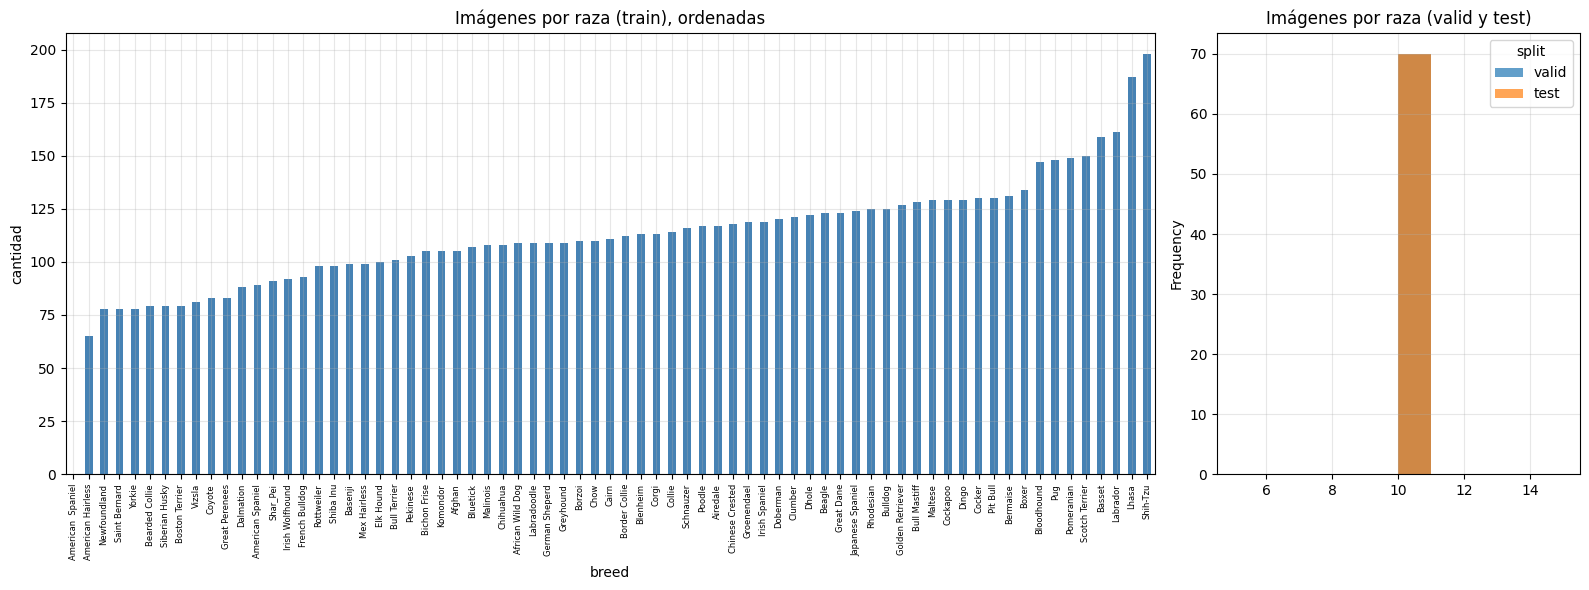


Razas con menos imágenes en train:
breed
American  Spaniel     0
American Hairless    65
Newfoundland         78
Saint Bernard        78
Yorkie               78


In [ ]:

rows = []
for split in SPLITS:
    for breed_dir in sorted(p for p in (DATASET_ROOT / split).iterdir() if p.is_dir()):
        for p in sorted(breed_dir.iterdir()):
            if p.suffix.lower() not in EXTS:
                continue
            row = {"split": split, "breed": breed_dir.name,
                   "path": p.relative_to(DATASET_ROOT).as_posix(),
                   "ext": p.suffix.lower(), "file_kb": p.stat().st_size / 1024}
            try:
                with Image.open(p) as im:
                    im.verify()                      # detecta archivos truncados/corruptos
                with Image.open(p) as im:            # verify() invalida el objeto: reabrir
                    row.update(width=im.width, height=im.height, mode=im.mode, corrupt=False)
            except Exception as exc:
                row.update(width=None, height=None, mode=None, corrupt=True, error=str(exc))
            rows.append(row)

df_meta = pd.DataFrame(rows)
df_meta.to_csv(settings.output_path / "dataset_meta.csv", index=False)

# --- Resumen general ---
print(f"Razas por split: {df_meta.groupby('split')['breed'].nunique().to_dict()}")
print(f"Imágenes por split: {df_meta['split'].value_counts().to_dict()}")
print(f"Archivos corruptos: {int(df_meta['corrupt'].sum())}")
print(f"Formatos: {df_meta['ext'].value_counts().to_dict()}")
print(f"Modos de color: {df_meta['mode'].value_counts(dropna=False).to_dict()}")
print(f"Resoluciones (ancho x alto): "
      f"{df_meta.groupby(['width', 'height']).size().sort_values(ascending=False).head(5).to_dict()}")

# --- Imágenes por raza en cada split ---
conteo = df_meta.pivot_table(index="breed", columns="split", values="path", aggfunc="count").fillna(0).astype(int)
print("\nEstadísticas de imágenes por raza:")
print(conteo[SPLITS].describe().loc[["mean", "50%", "min", "max"]].round(1).rename(index={"50%": "median"}))

# Consistencia: ¿las razas son las mismas en los tres splits?
razas = {s: set(df_meta.loc[df_meta.split == s, "breed"]) for s in SPLITS}
print("\nRazas idénticas en train/valid/test:", razas["train"] == razas["valid"] == razas["test"])


print("\nRazas con menos imágenes en train:")
print(conteo["train"].sort_values().head(5).to_string())

In [ ]:
for s in SPLITS:
    nombres = sorted(p.name for p in (DATASET_ROOT / s).iterdir() if p.is_dir())
    print(s, len(nombres), [repr(n) for n in nombres if "spaniel" in n.lower()])

print("Solo en train:", sorted(razas["train"] - razas["valid"]))
print("Solo en valid:", sorted(razas["valid"] - razas["train"]))
print("Solo en test: ", sorted(razas["test"] - razas["train"]))

train 70 ["'American Spaniel'", "'Irish Spaniel'", "'Japanese Spaniel'"]
valid 70 ["'American  Spaniel'", "'Irish Spaniel'", "'Japanese Spaniel'"]
test 70 ["'American Spaniel'", "'Irish Spaniel'", "'Japanese Spaniel'"]
Solo en train: ['American Spaniel']
Solo en valid: ['American  Spaniel']
Solo en test:  []


### Análisis inicial del dataset

El conjunto contiene 9.346 imágenes distribuidas en 70 razas, con 7.946 imágenes para entrenamiento y 700 para cada uno de los conjuntos de validación y prueba.

En cuanto a las características de los archivos, todas las imágenes están en formato JPG, tienen una resolución de 224 × 224 píxeles y utilizan el espacio de color RGB. La verificación realizada no detectó archivos corruptos.

La distribución de imágenes no es uniforme entre las razas. En entrenamiento, la cantidad varía entre 65 y 198 imágenes por clase.

También se detectó una diferencia en el nombre de una clase: `American Spaniel` aparece como `American  Spaniel` en validación, con un espacio adicional. Aunque ambos nombres representan la misma raza, el análisis los interpreta como clases distintas. Esta inconsistencia explica por qué la comparación inicial de las clases entre particiones devuelve `False` y debe corregirse antes de continuar.

Normalizamos nombres de raza `American  Spaniel`

In [ ]:
# Se corrige solo la etiqueta; la columna 'path' conserva la ruta real en disco.
df_meta["breed"] = df_meta["breed"].map(lambda s: " ".join(s.split()))
razas = {s: set(df_meta.loc[df_meta.split == s, "breed"]) for s in SPLITS}
assert razas["train"] == razas["valid"] == razas["test"] and len(razas["train"]) == 70
CLASSES = sorted(razas["train"])                       # única fuente de verdad índice -> raza
CLASS_TO_IDX = {b: i for i, b in enumerate(CLASSES)}

conteo = df_meta.pivot_table(index="breed", columns="split", values="path",
                             aggfunc="count", fill_value=0)[SPLITS]
print(conteo.describe().loc[["mean", "std", "min", "50%", "max"]].round(1))
tr = conteo["train"]
print(f"\nDesbalance en train: max/min = {tr.max() / tr.min():.2f} | coef. de variación = {tr.std() / tr.mean():.2f}")
print("Menos representadas:\n", tr.nsmallest(5).to_string())
print("Más representadas:\n", tr.nlargest(5).to_string())
print("¿valid y test con exactamente 10 por raza?:", bool((conteo[["valid", "test"]] == 10).all().all()))



split  train  valid  test
mean   113.5   10.0  10.0
std     24.7    0.0   0.0
min     65.0   10.0  10.0
50%    111.5   10.0  10.0
max    198.0   10.0  10.0

Desbalance en train: max/min = 3.05 | coef. de variación = 0.22
Menos representadas:
 breed
American Hairless    65
Newfoundland         78
Saint Bernard        78
Yorkie               78
Bearded Collie       79
Más representadas:
 breed
Shih-Tzu          198
Lhasa             187
Labrador          161
Basset            159
Scotch Terrier    150
¿valid y test con exactamente 10 por raza?: True


### Características y limitaciones del dataset

El dataset contiene 70 razas de perros, organizadas en directorios que corresponden a las particiones de entrenamiento, validación y prueba. Las imágenes tienen formato JPG, resolución de 224 × 224 píxeles y tres canales de color.

**Limitaciones identificadas**

- Algunas razas presentan características visuales similares, lo que puede generar confusiones durante la clasificación.
- Las fotografías provienen de distintas fuentes y pueden presentar diferencias de iluminación, pose y fondo.
- El conjunto principal contiene imágenes de perros de razas definidas, por lo que no representa adecuadamente casos de perros mestizos o imágenes sin perros.
- Validación y test cuentan con solo 10 imágenes por raza, por lo que las métricas individuales deben interpretarse teniendo en cuenta ese tamaño reducido.

**Distribución de clases**

En entrenamiento, la cantidad de imágenes por raza varía entre 65 y 198. El cociente entre la clase más representada y la menos representada es de 3,05, con un coeficiente de variación de 0,22. Existe, por lo tanto, un desbalance moderado entre clases que debe considerarse durante el entrenamiento.

## 6. Análisis exploratorio (EDA)

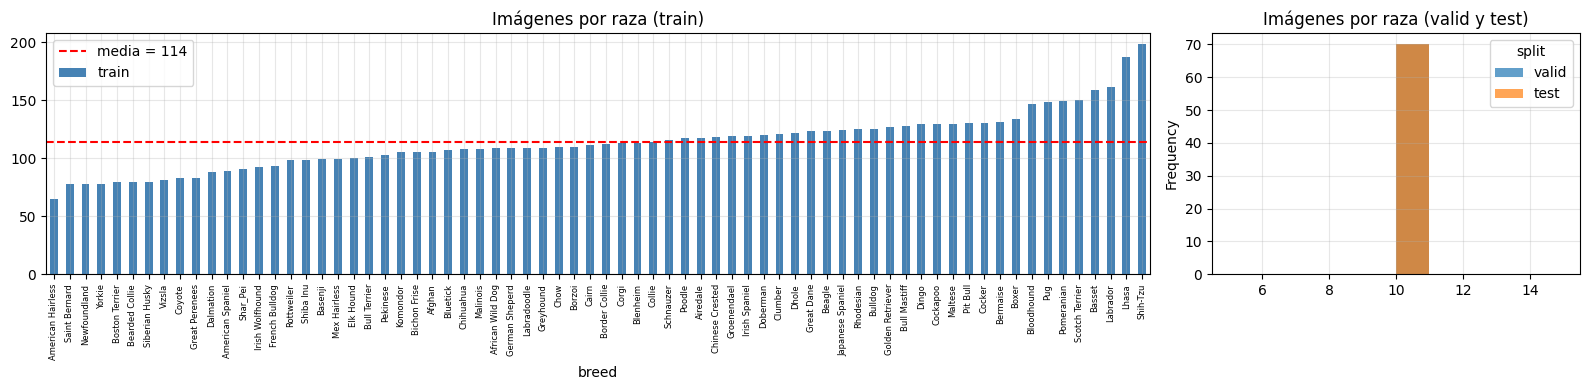

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={"width_ratios": [3, 1]})
tr.sort_values().plot.bar(ax=axes[0], color="steelblue")
axes[0].axhline(tr.mean(), color="red", ls="--", label=f"media = {tr.mean():.0f}")
axes[0].set_title("Imágenes por raza (train)"); axes[0].tick_params(axis="x", labelsize=6); axes[0].legend()
conteo[["valid", "test"]].plot.hist(ax=axes[1], bins=range(5, 16), alpha=0.7)
axes[1].set_title("Imágenes por raza (valid y test)")
plt.tight_layout(); plt.show()

El gráfico permite observar el desbalance en entrenamiento.

In [ ]:
df_meta["aspect"] = df_meta["width"] / df_meta["height"]
print("Formatos:", df_meta["ext"].value_counts().to_dict())
print("Modos de color:", df_meta["mode"].value_counts().to_dict())
print("Corruptos:", int(df_meta["corrupt"].sum()))
print("Resoluciones distintas:", df_meta.groupby(["width", "height"]).ngroups)
print(df_meta[["width", "height", "aspect", "file_kb"]].describe().round(2).loc[["min", "50%", "max"]])
print("\nPeso mediano (KB) por split:\n", df_meta.groupby("split")["file_kb"].median().round(1).to_string())

Formatos: {'.jpg': 9346}
Modos de color: {'RGB': 9346}
Corruptos: 0
Resoluciones distintas: 1
     width  height  aspect  file_kb
min  224.0   224.0     1.0     8.60
50%  224.0   224.0     1.0    23.23
max  224.0   224.0     1.0    46.35

Peso mediano (KB) por split:
 split
test     23.0
train    23.2
valid    23.8


La salida confirma que:
- Las 9.346 imágenes son JPG.
- Todas están en RGB.
- Hay una sola resolución: 224 × 224.
- No se detectaron imágenes corruptas.
- La relación de aspecto es 1

### Grillas de ejemplos y pares confundibles


In [ ]:
def read_rgb(rel_path):
    return cv2.cvtColor(cv2.imread(str(DATASET_ROOT / rel_path)), cv2.COLOR_BGR2RGB)

def show_imgs(rel_paths, captions, ncols=8, title=None, size=2.0):
    nrows = int(np.ceil(len(rel_paths) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * (size + 0.4)), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, p, c in zip(axes.ravel(), rel_paths, captions):
        ax.imshow(read_rgb(p)); ax.set_title(c, fontsize=6)
    if title:
        fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
train_paths = {b: df_meta.loc[(df_meta.split == "train") & (df_meta.breed == b), "path"].to_numpy() for b in CLASSES}

# 1) Mosaico: una imagen por raza (70)
show_imgs([rng.choice(train_paths[b]) for b in CLASSES], CLASSES, ncols=10, size=1.6,
          title="Una imagen por raza (train)")


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
# 2) Pares fáciles de confundir: 6 ejemplos de cada raza
def find_breed(q):
    exact = [b for b in CLASSES if b.lower() == q.lower()]
    part = [b for b in CLASSES if q.lower() in b.lower()]
    return (exact or part or [None])[0]

CANDIDATE_PAIRS = [("Cockapoo", "Labradoodle"), ("Border Collie", "Collie"),
                   ("Vizsla", "Rhodesian"), ("Pekinese", "Shih-Tzu"),
                   ("Maltese", "Bichon Frise"), ("Cocker", "Blenheim")]
for qa, qb in CANDIDATE_PAIRS:
    a, b = find_breed(qa), find_breed(qb)
    if a is None or b is None:
        print(f"[omitido] no encontré {qa!r} o {qb!r}. Razas disponibles:\n{CLASSES}")
        continue
    ps = list(rng.choice(train_paths[a], 6, replace=False)) + list(rng.choice(train_paths[b], 6, replace=False))
    show_imgs(ps, [a] * 6 + [b] * 6, ncols=6, size=2.0, title=f"{a}  vs  {b}")

Output hidden; open in https://colab.research.google.com to view.

### Análisis de similitud visual entre razas

A partir de la inspección del mosaico general de las 70 razas, se seleccionaron seis pares de clases que presentan características físicas potencialmente confundibles.

Para cada par se generó una grilla de comparación con seis imágenes de cada raza, seleccionadas aleatoriamente del conjunto de entrenamiento. Esto permite observar tanto las similitudes entre clases como la variabilidad de las imágenes pertenecientes a una misma clase.

**Similitudes entre razas**

Se identifican pares que comparten atributos, como la forma del hocico, las dimensiones corporales, la estructura de las orejas y las características del pelaje. Algunos ejemplos son Maltese y Bichon Frise, Pekinese y Shih-Tzu, y Cockapoo y Labradoodle.

Estas similitudes pueden dificultar la diferenciación entre determinadas razas, especialmente cuando las imágenes no muestran con claridad sus características distintivas.

**Variabilidad dentro de una misma raza**

También se observa variabilidad considerable entre imágenes de una misma raza. Esta se manifiesta en diferencias de color, longitud y pelaje, postura, orientación, encuadre e iluminación.

Esta variabilidad representa un desafío adicional para el clasificador, ya que debe reconocer características representativas de cada raza independientemente de las condiciones particulares de la fotografía.

**Heterogeneidad de las imágenes**

Las fotografías presentan diferencias en sus fondos, iluminación, distancia de captura y proporción del animal dentro de la imagen.

**Implicancias para la clasificación**

La similitud interclase y la variabilidad intraclase constituyen posibles fuentes de error para el modelo. Por este motivo, los pares seleccionados se consideran candidatos para analizar posteriormente los errores de clasificación.

Esta inspección constituye un análisis exploratorio cualitativo. Es necesario un analisis detallado para la identificación de las razas que efectivamente generan mayor confusión.

In [ ]:
def dhash64(gray):
    """Hash perceptual de diferencias: compara píxeles vecinos de una miniatura 9x8 -> 64 bits."""
    small = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA)
    bits = (small[:, 1:] > small[:, :-1]).flatten()
    return np.frombuffer(np.packbits(bits).tobytes(), dtype=np.uint64)[0]

feats = []
for r in tqdm(df_meta.itertuples(), total=len(df_meta)):
    f = dict(brightness=np.nan, contrast=np.nan, lap_var=np.nan,
             frac_dark=np.nan, frac_bright=np.nan, dhash=np.uint64(0), md5="")
    if not r.corrupt:
        raw = (DATASET_ROOT / r.path).read_bytes()
        gray = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_GRAYSCALE)
        if gray is not None:
            f.update(md5=hashlib.md5(raw).hexdigest(),
                     brightness=gray.mean(), contrast=gray.std(),
                     lap_var=cv2.Laplacian(gray, cv2.CV_64F).var(),
                     frac_dark=(gray < 10).mean(), frac_bright=(gray > 245).mean(),
                     dhash=dhash64(gray))
    feats.append(f)

df_feat = pd.concat([df_meta.reset_index(drop=True), pd.DataFrame(feats)], axis=1)
df_feat["corrupt"] = df_feat["corrupt"] | df_feat["brightness"].isna()

# --- Distribuciones de iluminación, contraste y nitidez ---
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col, t in zip(axes, ["brightness", "contrast", "lap_var"],
                      ["Brillo medio (0-255)", "Contraste (desvío del gris)", "Nitidez: varianza del Laplaciano (log)"]):
    for s in SPLITS:
        ax.hist(df_feat.loc[df_feat.split == s, col].dropna(), bins=50, alpha=0.5, density=True, label=s,
                log=False)
    ax.set_title(t)
    if col == "lap_var":
        ax.set_xscale("log")
axes[0].legend(); plt.tight_layout(); plt.show()
print(df_feat.groupby("split")[["brightness", "contrast", "lap_var"]].median().round(1))

# --- Muestra aleatoria para inspeccionar pose, fondo, oclusiones y cantidad de perros ---
muestra = df_feat[df_feat.split == "train"].sample(32, random_state=42)
show_imgs(muestra["path"].tolist(), muestra["breed"].tolist(), ncols=8, size=1.9,
          title="Muestra aleatoria de train (seed=42)")

Output hidden; open in https://colab.research.google.com to view.

### Análisis de las características visuales de las imágenes

Se analizaron tres características de las imágenes: brillo medio, contraste y nitidez, con el objetivo de identificar posibles problemas de calidad que pudieran afectar el entrenamiento del modelo.

Las distribuciones permiten observar la heterogeneidad de las condiciones visuales del conjunto. Sin embargo, estas métricas deben interpretarse con cautela, ya que valores extremos no necesariamente indican imágenes defectuosas.

Por este motivo, las métricas se utilizarán como indicadores iniciales para la detección de posibles imágenes problemáticas.

### 7. Control de calidad y filtrado

En esta etapa se implementaron controles para identificar imágenes que pudieran afectar la calidad del conjunto de datos o introducir problemas durante el entrenamiento.

v1 marca 89 imágenes. Con fondo uniforme blanco/negro: 37
Sin fondo de estudio (a revisar): 52
       marcadas  fondo_estudio
split                         
test          1              1
train        86             36
valid         2              0


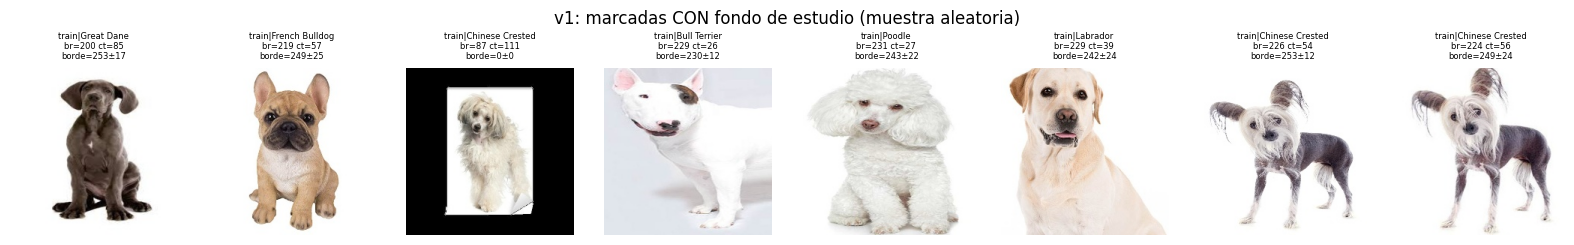

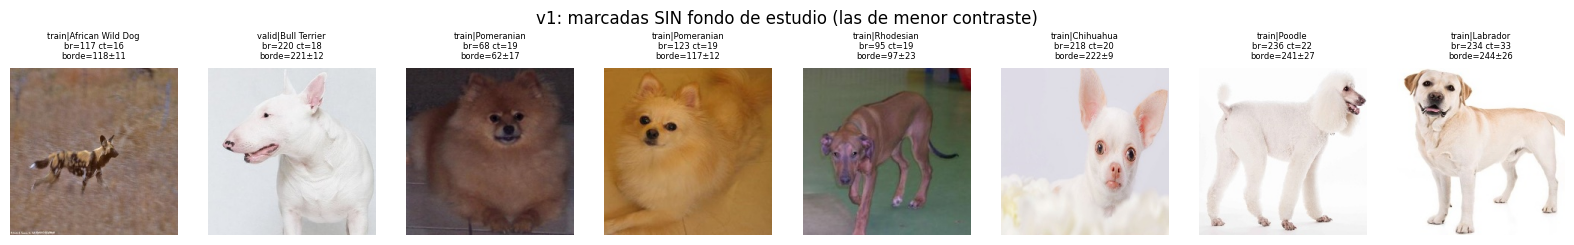


v2 (contraste < 12) marca: 0


In [ ]:
# ---- Regla de exposición v1 (exploratoria): se conserva solo para documentar la iteración ----
df = df_feat.copy()
df["r_exposure_v1"] = ((df["brightness"] < 30) | (df["brightness"] > 225)
                       | (df["contrast"] < 20)
                       | ((df["frac_dark"] + df["frac_bright"]) > 0.60))

def border_stats(rel_path, m=0.10):
    """Media y desvío del gris en el marco exterior (10% de cada lado)."""
    g = cv2.imread(str(DATASET_ROOT / rel_path), cv2.IMREAD_GRAYSCALE)
    h, w = g.shape; b = int(min(h, w) * m)
    ring = np.ones_like(g, dtype=bool); ring[b:h - b, b:w - b] = False
    return g[ring].mean(), g[ring].std()

v1 = df[df["r_exposure_v1"]].copy()
v1[["bg_mean", "bg_std"]] = [border_stats(p) for p in v1["path"]]
# Fondo de estudio = marco casi uniforme y casi blanco o casi negro
v1["fondo_estudio"] = (v1["bg_std"] < 25) & ((v1["bg_mean"] > 225) | (v1["bg_mean"] < 40))

print(f"v1 marca {len(v1)} imágenes. Con fondo uniforme blanco/negro: {int(v1.fondo_estudio.sum())}")
print(f"Sin fondo de estudio (a revisar): {int((~v1.fondo_estudio).sum())}")
print(v1.groupby("split").fondo_estudio.agg(["size", "sum"]).rename(columns={"size": "marcadas", "sum": "fondo_estudio"}))

# Evidencia visual con los valores en el título
def show_with_values(sub, title, n=8):
    sub = sub.head(n)
    caps = [f"{r.split}|{r.breed}\nbr={r.brightness:.0f} ct={r.contrast:.0f}\nborde={r.bg_mean:.0f}±{r.bg_std:.0f}"
            for r in sub.itertuples()]
    show_imgs(sub["path"].tolist(), caps, ncols=8, title=title)

show_with_values(v1[v1.fondo_estudio].sample(8, random_state=0), "v1: marcadas CON fondo de estudio (muestra aleatoria)")
show_with_values(v1[~v1.fondo_estudio].sort_values("contrast"), "v1: marcadas SIN fondo de estudio (las de menor contraste)")

# ---- Regla v2 (final) ----
LOW_CONTRAST_STD = 12
df["r_exposure"] = df["contrast"] < LOW_CONTRAST_STD
print("\nv2 (contraste < 12) marca:", int(df["r_exposure"].sum()))

#### Evaluación de los criterios de exposición

Inicialmente se evaluó los valores extremos de brillo, bajo contraste y proporción de píxeles muy oscuros o muy claros.

Esta primera aproximación identificó 89 imágenes. Sin embargo, la inspección visual mostró que 37 correspondían a fotografías con fondos uniformes blancos o negros, mientras que las 52 restantes presentaban características que no justificaban su descarte automático.

Esto evidenció que los valores extremos de brillo no necesariamente representan defectos de calidad, ya que pueden responder a las condiciones propias de la fotografía.

Por este motivo, se descartó esta medida exploratoria y se adoptó un criterio más restrictivo, basado exclusivamente en el contraste. Con el umbral definido de 12 no se identificaron imágenes para descartar.

En consecuencia, se evitó eliminar fotografías potencialmente válidas por sus características de iluminación o composición.

In [ ]:
# ============== Parámetros (todos en un solo lugar, para que sea reproducible) ==============
MIN_SIDE = 100            # lado mínimo en px
BLUR_LAP_VAR = 30.0       # var. del Laplaciano; con 50 marcaba fotos nítidas con fondo plano
LOW_CONTRAST_STD = 12     # solo imágenes casi uniformes; brillo/saturación se descartaron (ver r_exposure_v1)
HASH_THR = 4              # distancia de Hamming máx. para casi-duplicado (de 64 bits)
DROP_EVAL_SPLITS = False  # False: valid/test solo se marcan, no se recortan

POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def hamming_pairs(h, thr, chunk=512):
    """Todos los pares (i<j) con distancia de Hamming <= thr, en bloques para no agotar memoria."""
    I, J, D = [], [], []
    for s in range(0, len(h), chunk):
        x = np.bitwise_xor(h[s:s + chunk, None], h[None, :])
        d = POP[x.view(np.uint8).reshape(x.shape + (8,))].sum(-1)
        ii, jj = np.nonzero(d <= thr)
        keep = jj > ii + s
        I.append(ii[keep] + s); J.append(jj[keep]); D.append(d[ii[keep], jj[keep]])
    return np.concatenate(I), np.concatenate(J), np.concatenate(D)

# df = df_feat.copy()
H = df["dhash"].to_numpy(dtype=np.uint64)
sp, breed, md5 = df["split"].to_numpy(), df["breed"].to_numpy(), df["md5"].to_numpy()

# ---- Reglas por imagen ----
df["r_corrupt"] = df["corrupt"]
df["r_lowres"] = (df[["width", "height"]].min(axis=1) < MIN_SIDE) & ~df["corrupt"]
df["r_blur"] = df["lap_var"] < BLUR_LAP_VAR
df["r_exposure"] = df["contrast"] < LOW_CONTRAST_STD


#  RULE_ORDER, keep, reporte y to_csv)
# ---- Reglas por pares: duplicados, casi-duplicados y etiquetas en conflicto ----
idx = np.flatnonzero(~df["corrupt"].to_numpy())
I, J, D = hamming_pairs(H[idx], HASH_THR)
I, J = idx[I], idx[J]
same_breed, same_md5 = breed[I] == breed[J], md5[I] == md5[J]

pairs = pd.DataFrame({"i": I, "j": J, "dist": D, "split_pair": ["-".join(sorted(t)) for t in zip(sp[I], sp[J])],
                      "same_breed": same_breed, "exact": same_md5})
print("Pares casi-duplicados por combinación de splits:")
print(pairs.groupby(["split_pair", "same_breed"]).size().to_string())

prio = df["split"].map({"test": 0, "valid": 1, "train": 2}).to_numpy()
loser = np.where(prio[I] > prio[J], I, J)      # pierde el más "train"; si empatan, el posterior

df["r_dup_exact"] = False
df["r_dup_near"] = False
df["r_label_conflict"] = False
df.loc[loser[same_breed & same_md5], "r_dup_exact"] = True
df.loc[loser[same_breed & ~same_md5], "r_dup_near"] = True
conf = ~same_breed
df.loc[np.concatenate([I[conf], J[conf]]), "r_label_conflict"] = True

# ---- Motivo de descarte (primera regla que aplica) y política por split ----
RULE_ORDER = ["r_corrupt", "r_lowres", "r_blur", "r_exposure", "r_dup_exact", "r_dup_near", "r_label_conflict"]
df["drop_reason"] = np.select([df[r] for r in RULE_ORDER], RULE_ORDER, default="")
droppable = (df["split"] == "train") | DROP_EVAL_SPLITS
df["keep"] = ~((df["drop_reason"] != "") & droppable)

# ---- Reporte ----
rep = pd.DataFrame({
    "marcadas": df[RULE_ORDER].sum(),
    "en_train": df[df.split == "train"][RULE_ORDER].sum(),
    "en_valid": df[df.split == "valid"][RULE_ORDER].sum(),
    "en_test": df[df.split == "test"][RULE_ORDER].sum(),
    "descartadas": [int(((df.drop_reason == r) & ~df.keep).sum()) for r in RULE_ORDER],
})
print("\n", rep)
print("\n", df.groupby("split").agg(total=("keep", "size"), conservadas=("keep", "sum")))
print("Mínimo de imágenes por raza en train tras limpiar:",
      int(df[df.keep & (df.split == "train")].groupby("breed").size().min()))

df.to_csv(settings.output_path / "dataset_quality.csv", index=False)
df[df.keep].to_csv(settings.output_path / "dataset_clean.csv", index=False)

Pares casi-duplicados por combinación de splits:
split_pair   same_breed
test-test    True            6
test-train   True           52
test-valid   True           10
train-train  False           7
             True          167
train-valid  True           60
valid-valid  True            4

                   marcadas  en_train  en_valid  en_test  descartadas
r_corrupt                0         0         0        0            0
r_lowres                 0         0         0        0            0
r_blur                   5         5         0        0            5
r_exposure               0         0         0        0            0
r_dup_exact            119       108         7        4          108
r_dup_near             145       137         7        1          133
r_label_conflict        14        14         0        0           14

        total  conservadas
split                    
test     700          700
train   7946         7686
valid    700          700
Mínimo de imágenes por r

#### Resultados del control de calidad

La aplicación de las reglas permitió identificar distintos tipos de problemas en el conjunto original.

Se detectaron 5 imágenes con baja nitidez, que fueron descartadas del conjunto de entrenamiento. No se encontraron archivos corruptos, imágenes con resolución inferior al mínimo establecido ni fotografías que cumplieran el criterio final de bajo contraste.

El principal problema identificado estuvo relacionado con la duplicación de imágenes.

También se identificaron 14 imágenes involucradas en pares con etiquetas diferentes, lo que representa un posible conflicto de etiquetado. Estos casos se excluyeron del conjunto de entrenamiento para evitar incorporar ejemplos ambiguos.

La política de filtrado priorizó la conservación de los conjuntos de validación y prueba, evitando eliminar imágenes de evaluación durante la limpieza general. Posteriormente, se aplicó un control específico para eliminar las coincidencias entre validación y prueba.

Los resultados muestran que la principal fuente de problemas no fue la calidad técnica de las fotografías, sino la presencia de imágenes repetidas y posibles inconsistencias en las etiquetas.

### Ejemplos de descarte

In [ ]:
def show_rule(rule, n=8, sort_col=None, ascending=True):
    sub = df[df[rule]]
    if sort_col:
        sub = sub.sort_values(sort_col, ascending=ascending)
    sub = sub.head(n)
    if sub.empty:
        print(f"{rule}: sin casos."); return
    caps = [f"{r.split}|{r.breed}\nlap={r.lap_var:.0f} br={r.brightness:.0f} ct={r.contrast:.0f}"
            for r in sub.itertuples()]
    show_imgs(sub["path"].tolist(), caps, ncols=8, title=f"{rule}  ({int(df[rule].sum())} marcadas)")

show_rule("r_blur", sort_col="lap_var")                     # las más borrosas primero
show_rule("r_exposure", sort_col="brightness")              # las más oscuras primero
show_rule("r_exposure", sort_col="brightness", ascending=False)

# Duplicados: pares (perdedora, ganadora); los de mayor distancia son los más dudosos
for name, mask in [("exactos", pairs.exact & pairs.same_breed), ("casi-duplicados", ~pairs.exact & pairs.same_breed),
                   ("conflicto de etiqueta", ~pairs.same_breed)]:
    sub = pairs[mask].sort_values("dist", ascending=False).head(6)
    if sub.empty:
        print(f"{name}: sin casos."); continue
    ps, cs = [], []
    for r in sub.itertuples():
        for k in (r.i, r.j):
            ps.append(df.at[k, "path"]); cs.append(f"{df.at[k, 'split']}|{df.at[k, 'breed']}|d={r.dist}")
    show_imgs(ps, cs, ncols=6, size=2.0, title=f"Pares {name}")

Output hidden; open in https://colab.research.google.com to view.

**Limitación de la detección automática de pares similares**

Durante la inspección visual de los pares identificados se observó que no todos corresponden a pares con conflicto de etiqueta. Algunos pares presentan similitudes visuales generales, pero representan fotografías diferentes. Esto evidencia que el umbral de distancia utilizado puede generar falsos positivos.

Por lo tanto, los pares detectados deben interpretarse como candidatos a imágenes similares y no como duplicados confirmados. Esta limitación también afecta la identificación de conflictos de etiqueta: dos imágenes de razas diferentes pueden ser marcadas como conflictivas por compartir características visuales, sin que necesariamente exista un error de etiquetado.

Dado que no se realizó un ajuste adicional del umbral ni una validación manual exhaustiva de todos los pares, los resultados de esta etapa deben considerarse una aproximación y no una identificación definitiva de duplicados o errores de clasificación.

### Chequeo Post-Limpieza

In [ ]:
import json

c = df[df.keep & ~df["corrupt"]].reset_index(drop=True)

# --- Verificación de fuga sobre el conjunto YA limpio ---
Hc = c["dhash"].to_numpy(dtype=np.uint64)
I2, J2, D2 = hamming_pairs(Hc, HASH_THR)
is_train = (c["split"] == "train").to_numpy()
cross = is_train[I2] != is_train[J2]            # un extremo en train y el otro en valid/test
print(f"Pares train <-> valid/test restantes (dist <= {HASH_THR}): {int(cross.sum())}")
assert cross.sum() == 0, "Quedó fuga de train hacia valid/test"
print("Duplicados residuales dentro de valid/test (se reportan, no se recortan):",
      int((~is_train[I2] & ~is_train[J2]).sum()))

# --- Etiquetas y CSVs finales ---
c["label"] = c["breed"].map(CLASS_TO_IDX)
assert c["label"].notna().all()
out = settings.output_path
for s in SPLITS:
    c.loc[c.split == s, ["path", "breed", "label"]].to_csv(out / f"{s}.csv", index=False)
(out / "classes.json").write_text(json.dumps(CLASSES, ensure_ascii=False, indent=2))

# --- Class weights (inverso de la frecuencia, normalizado) ---
n_c = c[c.split == "train"].groupby("label").size().reindex(range(len(CLASSES)))
class_weights = (n_c.sum() / (len(CLASSES) * n_c)).to_numpy().astype("float32")
np.save(out / "class_weights.npy", class_weights)
print(c.groupby("split").size().to_dict(),
      "| peso mín/máx:", class_weights.min().round(2), class_weights.max().round(2))

Pares train <-> valid/test restantes (dist <= 4): 0
Duplicados residuales dentro de valid/test (se reportan, no se recortan): 20
{'test': 700, 'train': 7686, 'valid': 700} | peso mín/máx: 0.57 1.74


## 8. Conjunto independiente de evaluación

### Objetivo del conjunto independiente

Se construyó un conjunto de evaluación independiente a partir de imágenes obtenidas de Wikimedia Commons, con el objetivo de evaluar el comportamiento del sistema sobre imágenes que no forman parte del dataset utilizado durante el entrenamiento, la validación ni la evaluación interna. Para las Etapas 1 y 2, se recopilaron 110 imágenes de perros correspondientes a 22 de las 70 razas del dataset original. Por lo tanto, la cobertura del conjunto independiente es parcial: no incluye la totalidad de las clases disponibles en el conjunto principal.

La incorporación de imágenes externas permite analizar la capacidad de generalización del sistema frente a fotografías provenientes de fuentes diferentes, que pueden presentar variaciones en las condiciones de iluminación, encuadre, fondo, resolución y perspectiva.

Se contemplan distintos escenarios de evaluación: imágenes que contienen un único perro, imágenes con varios perros y/o personas y imágenes sin perros, para comprobar si el sistema puede reconocer situaciones en las que no corresponde realizar una clasificación de raza.


In [ ]:
import re, time, html, requests
from datetime import date

INDEP = settings.dataset_path / "independent"
API = "https://commons.wikimedia.org/w/api.php"
HEADERS = {"User-Agent": "TP-RazasPerros/1.0 (uso academico; contacto: guillermo.nicolas,ricci@gmail.com)"}
OK_LICENSE = ("cc by", "cc0", "public domain")

BREEDS= [
    "Beagle", "Poodle", "Bluetick", "Pug", "French Bulldog", "Shih-Tzu", "Lhasa",
    "Labrador", "Golden Retriever", "Chihuahua", "Pekinese", "Basset",
    "Boxer", "Chow", "Doberman", "German Sheperd", "Vizsla",
    "Pomeranian", "Rottweiler", "Saint Bernard", "Yorkie", "Bloodhound"
]

SEARCH_TERM = {"Great Perenees": "Great Pyrenees", "Yorkie": "Yorkshire Terrier",
              "German Sheperd":"German Shepherd","Basset":"Basset Hound" , "Lhasa":"Lhasa Apso",}                  # nombre del dataset -> término de búsqueda
PER_BREED = 5

faltan = [b for b in BREEDS if b not in CLASSES]
assert not faltan, f"No están en CLASSES: {faltan}\n{CLASSES}"

def clean(s):
    return re.sub(r"\s+", " ", re.sub(r"<[^>]+>", "", html.unescape(s or ""))).strip()

def search_commons(query, limit=40):
    params = dict(action="query", format="json", generator="search", gsrnamespace=6, gsrlimit=limit,
                  gsrsearch=f"{query} filetype:bitmap", prop="imageinfo",
                  iiprop="url|mime|size|extmetadata", iiurlwidth=640)
    r = requests.get(API, params=params, headers=HEADERS, timeout=30); r.raise_for_status()
    pages = r.json().get("query", {}).get("pages", {})
    return sorted(pages.values(), key=lambda p: p.get("index", 0))

def download(query, folder, prefix, label, kind, n):
    out = INDEP / folder; out.mkdir(parents=True, exist_ok=True)
    got, rows = 0, []
    for p in search_commons(query):
        info = p["imageinfo"][0]; meta = info.get("extmetadata", {})
        lic = clean(meta.get("LicenseShortName", {}).get("value", ""))
        if info["mime"] != "image/jpeg" or info["width"] < 400 or not lic.lower().startswith(OK_LICENSE):
            continue
        fname = f"{prefix}_{got + 1:03d}.jpg"
        img = requests.get(info["thumburl"], headers=HEADERS, timeout=60); img.raise_for_status()
        (out / fname).write_bytes(img.content)
        rows.append(dict(path=f"{folder}/{fname}", breed=label, type=kind,
                         source_url=info["descriptionurl"], author=clean(meta.get("Artist", {}).get("value", "")),
                         license=lic, date_accessed=date.today().isoformat()))
        got += 1; time.sleep(0.5)
        if got >= n:
            break
    print(f"{folder}: {got} candidatas")
    return rows

rows = []
for b in BREEDS:
    rows += download(f"{SEARCH_TERM.get(b, b)} dog", b, b.lower().replace(" ", "_"), b, "single", PER_BREED)

# Etapa 3: escenas con varios perros / personas, y escenas sin perros
for i, q in enumerate(["dogs playing park"]):
    rows += download(q, "_multi_dogs", f"multi{i}", "", "multi", 10)
for i, q in enumerate(["cat", "horse", "birds"]):
    rows += download(q, "_no_dogs", f"none{i}", "", "none", 3)

pd.DataFrame(rows).to_csv(INDEP / "metadata_candidates.csv", index=False)

Beagle: 5 candidatas
Poodle: 5 candidatas
Bluetick: 5 candidatas
Pug: 5 candidatas
French Bulldog: 5 candidatas
Shih-Tzu: 5 candidatas
Lhasa: 5 candidatas
Labrador: 5 candidatas
Golden Retriever: 5 candidatas
Chihuahua: 5 candidatas
Pekinese: 5 candidatas
Basset: 5 candidatas
Boxer: 5 candidatas
Chow: 5 candidatas
Doberman: 5 candidatas
German Sheperd: 5 candidatas
Vizsla: 5 candidatas
Pomeranian: 5 candidatas
Rottweiler: 5 candidatas
Saint Bernard: 5 candidatas
Yorkie: 5 candidatas
Bloodhound: 5 candidatas
_multi_dogs: 10 candidatas
_no_dogs: 3 candidatas
_no_dogs: 3 candidatas
_no_dogs: 3 candidatas


Descargamos el dataset para verificar las imagenes y editar o quitar las fotos que no sean correctas.

In [ ]:
import shutil
from google.colab import files
from pathlib import Path

# Ruta a la carpeta independent dentro del dataset
independent_path = Path(settings.dataset_path) / "independent"
zip_output_name = "independent_dataset"

if independent_path.exists():
    print(f"Comprimiendo {independent_path} ...")
    # Crea independent_dataset.zip
    shutil.make_archive(zip_output_name, 'zip', independent_path)
    print("¡Compresión completada! Iniciando descarga de independent_dataset.zip...")

    # Descarga el archivo zip generado a tu escritorio
    files.download(f"{zip_output_name}.zip")
else:
    print(f"❌ No se encontró la carpeta en {independent_path}. Asegúrate de haber ejecutado la descarga de imágenes primero.")

Comprimiendo data/dataset/independent ...
¡Compresión completada! Iniciando descarga de independent_dataset.zip...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

El dataset fue revisado manualmente, se puede encontrar el dataset limpio en:

https://drive.google.com/drive/folders/1YIavXBidJr8pwDT1KM4mAmbxxO5yKX_H?usp=sharing

In [ ]:
import shutil
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")
SRC = Path("/content/drive/MyDrive/TUIA/COMPUTER VISION/DOG RECOGNITION/Datasets/independent_dataset")
INDEP = Path(settings.dataset_path) / "independent"

if INDEP.exists():
    shutil.rmtree(INDEP)
shutil.copytree(SRC, INDEP)

# Usamos encoding='latin1' para evitar errores con caracteres especiales en el CSV
meta = pd.read_csv(INDEP / "metadata_candidates.csv", encoding='latin1')
EXTS = {".jpg", ".jpeg", ".png"}
en_disco = {p.relative_to(INDEP).as_posix() for p in INDEP.rglob("*") if p.suffix.lower() in EXTS}
print("En el CSV pero no en disco:", sorted(set(meta.path) - en_disco))
print("En disco pero no en el CSV:", sorted(en_disco - set(meta.path)))

single = meta[meta.type == "single"]
print("Razas fuera de CLASSES:", sorted(set(single.breed) - set(CLASSES)))
print(f"{len(single)} limpias | {single.breed.nunique()} razas | minimo por raza: {single.groupby('breed').size().min()}")
print("multi:", int((meta.type == "multi").sum()), "| sin perros:", int((meta.type == "none").sum()))
print(meta.license.value_counts().to_string())
assert not (set(meta.path) ^ en_disco), "CSV y carpetas no coinciden"
assert set(single.breed) <= set(CLASSES)
assert len(single) >= 100 and single.breed.nunique() >= 20
for col in ["source_url", "author", "license"]:
    assert meta[col].notna().all(), f"falta {col}"

Mounted at /content/drive
En el CSV pero no en disco: []
En disco pero no en el CSV: []
Razas fuera de CLASSES: []
110 limpias | 22 razas | minimo por raza: 5
multi: 10 | sin perros: 9
license
CC BY-SA 4.0     43
CC BY 2.0        22
CC BY-SA 3.0     19
CC0              12
CC BY 3.0         9
Public domain     9
CC BY-SA 2.0      7
CC BY 4.0         6
CC BY 2.5         1
CC BY-SA 2.5      1


Chequeo de fuga de datos

In [ ]:
meta = pd.read_csv(INDEP / "metadata_candidates.csv")
ind_h = np.array([dhash64(cv2.imread(str(INDEP / p), cv2.IMREAD_GRAYSCALE)) for p in meta.path], dtype=np.uint64)
ref_h = df["dhash"].to_numpy(dtype=np.uint64)

x = np.bitwise_xor(ind_h[:, None], ref_h[None, :])
d = POP[x.view(np.uint8).reshape(x.shape + (8,))].sum(-1)
meta["min_dist"] = d.min(1)
meta["closest"] = df["path"].to_numpy()[d.argmin(1)]
print("Imágenes a distancia <= 4 de alguna del dataset:", int((meta.min_dist <= HASH_THR).sum()))
print(meta[meta.min_dist <= HASH_THR][["path", "min_dist", "closest"]].to_string())

for col in ["source_url", "author", "license"]:
    assert meta[col].notna().all() and (meta[col].astype(str).str.len() > 0).all(), f"falta {col}"

Imágenes a distancia <= 4 de alguna del dataset: 0
Empty DataFrame
Columns: [path, min_dist, closest]
Index: []


## 9. Preprocesamiento


In [ ]:
import cv2, numpy as np
import torchvision.transforms as T
from lib.preprocessing import preprocess_bgr

path = DATASET_ROOT / df_meta.loc[df_meta.split == "train", "path"].iloc[0]
mine = preprocess_bgr(cv2.imread(str(path)), image_size=224)

ref_tf = T.Compose([T.Resize((224, 224)), T.ToTensor(),
                    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
ref = ref_tf(Image.open(path).convert("RGB")).numpy()

print("shape:", mine.shape, "| dtype:", mine.dtype)
print("diferencia máxima vs. torchvision/PIL:", float(np.abs(mine - ref).max()))
assert mine.shape == (3, 224, 224) and np.abs(mine - ref).max() < 0.05

shape: (3, 224, 224) | dtype: float32
diferencia máxima vs. torchvision/PIL: 0.0


### Verificación del preprocesamiento
El pipeline de `lib/preprocessing.py` (BGR→RGB, resize, normalización ImageNet) se comparó con el pipeline estándar de torchvision/PIL sobre una imagen de train.

Como resultado obtuvimos:
* Misma forma: (3, 224, 224)
* Mismo tipo: dtype float32
* diferencia máxima 0.0.

El mismo módulo se importa en el entrenamiento y en los servicios de la app, para evitar el desfase entre notebook e inferencia.

In [ ]:
import random, torch
from lib.preprocessing import IMAGENET_MEAN, IMAGENET_STD

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

# Estadísticas de train (solo imágenes conservadas), en RGB y escala [0,1]
train_clean = df[df.keep & (df.split == "train")]
s1, s2 = np.zeros(3), np.zeros(3)
for p in tqdm(train_clean.path):
    x = read_rgb(p).astype(np.float64) / 255.0
    s1 += x.mean((0, 1)); s2 += (x ** 2).mean((0, 1))
mean_train = s1 / len(train_clean)
std_train = np.sqrt(s2 / len(train_clean) - mean_train ** 2)

print(pd.DataFrame({"ImageNet_mean": IMAGENET_MEAN, "train_mean": mean_train,
                    "ImageNet_std": IMAGENET_STD, "train_std": std_train}, index=list("RGB")).round(3))
print("Diferencia máxima en la media:", float(np.abs(mean_train - IMAGENET_MEAN).max()).__round__(3),
      "| en el desvío:", float(np.abs(std_train - IMAGENET_STD).max()).__round__(3))

  0%|          | 0/7686 [00:00<?, ?it/s]

   ImageNet_mean  train_mean  ImageNet_std  train_std
R          0.485       0.524         0.229      0.273
G          0.456       0.489         0.224      0.268
B          0.406       0.421         0.225      0.275
Diferencia máxima en la media: 0.039 | en el desvío: 0.05


**Orden de canales:** la app entrega BGR (OpenCV); el módulo convierte a RGB una sola vez, antes del resize.

**Resize:** resize directo a 224×224. En el dataset es la identidad (todas ya son 224×224). Para los
recortes de YOLO (Etapa 3) el módulo ofrece `mode="pad"`, que conserva la relación de aspecto; se comparará
con el resize directo sobre el conjunto independiente.

**Normalización:** (x/255 − media)/desvío con estadísticas de ImageNet en los tres modelos.
Las estadísticas de train difieren poco *(media máx. 0.039, desvío máx. 0.05)*.
Para el **Modelo A** ImageNet es obligatorio por los pesos preentrenados. Para la **CNN propia**
se usa lo mismo porque un único
pipeline en notebooks y app evita errores de desfase entre entrenamiento e inferencia.

## 10. Data augmentation


| Transformación       | Rango             | Por qué |
|----------------------|-------------------|---------|
| Flip horizontal      | p = 0.5           | Invierte la imagen horizontalmente para generar distintas orientaciones del perro. |
| Rotación             | ±15°              | Gira la imagen para simular diferentes ángulos de captura. |
| Blur gaussiano       | kernel 3-5, p=0.2 | Desenfoca ligeramente la imagen para simular imperfecciones de enfoque. |
| Brillo y contraste   | ±20 %             | Modifica la iluminación y el contraste para simular distintas condiciones de luz. |
| Ruido gaussiano      | leve, p=0.3       | Agrega pequeñas variaciones en los píxeles para simular ruido de cámara. |

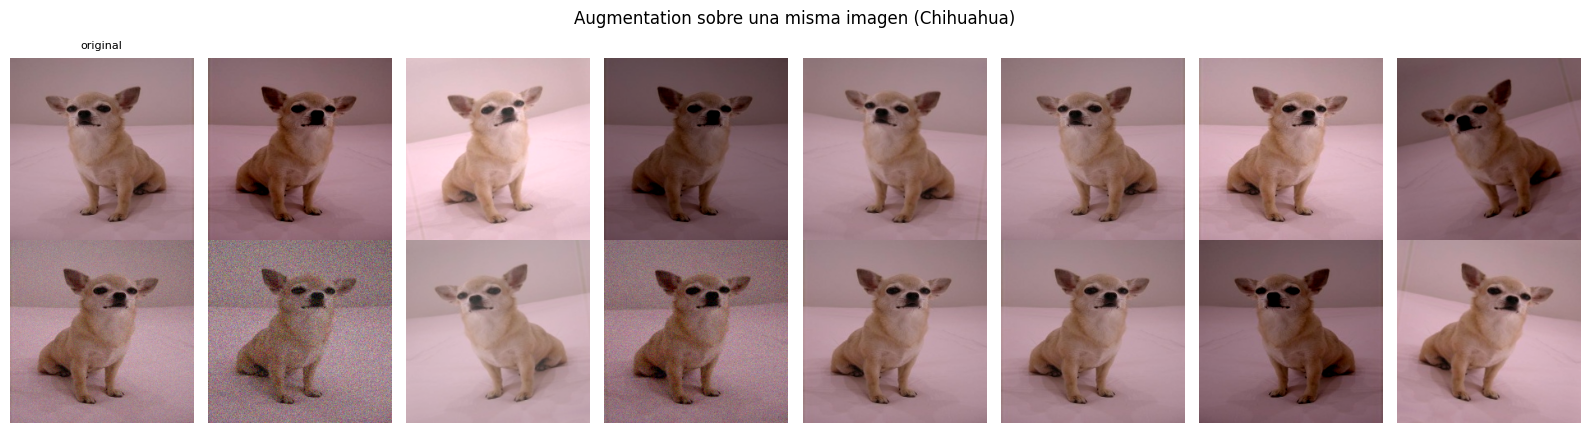

shape: (3, 224, 224) | dtype: float32


In [ ]:
import importlib, lib.augmentation as aug_mod
importlib.reload(aug_mod)
from lib.augmentation import build_train_augmentation
from lib.preprocessing import normalize_rgb_uint8

AUG = build_train_augmentation()

# Una misma imagen de train, 15 variantes aumentadas
ejemplo = df[(df.split == "train") & df.keep].sample(1, random_state=SEED).iloc[0]
rgb = read_rgb(ejemplo.path)
set_seed()
variantes = [AUG(image=rgb)["image"] for _ in range(15)]

fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].imshow(rgb); axes[0, 0].set_title("original", fontsize=8)
for ax, v in zip(axes.ravel()[1:], variantes):
    ax.imshow(v)
fig.suptitle(f"Augmentation sobre una misma imagen ({ejemplo.breed})"); plt.tight_layout(); plt.show()

# Chequeo: la salida pasa por la MISMA normalización que la inferencia
x = normalize_rgb_uint8(variantes[0])
print("shape:", x.shape, "| dtype:", x.dtype)

### Inspección visual de las transformaciones

La grilla permite observar distintas variantes generadas a partir de una misma imagen original.

La inspección visual permite comprobar que las transformaciones introducen variabilidad sin modificar sustancialmente el contenido semántico de la imagen.


## 11. Splits


### Control de fuga de datos entre conjuntos

Durante el análisis de pares confundibles y casi duplicados se identificaron coincidencias entre los distintos subconjuntos del dataset.

La presencia de estas coincidencias representa un posible problema de fuga de datos (*data leakage*), ya que una misma imagen o una variante visual prácticamente idéntica podría intervenir en más de una instancia de evaluación.

Por este motivo, se decidió conservar las imágenes de test y eliminar las copias correspondientes de validación.

De esta manera, se busca preservar la independencia del conjunto de test y evitar que las coincidencias detectadas afecten la evaluación final.


In [ ]:
DROP_VALID_DUPS_OF_TEST = True    # False: queda como limitación declarada

final = df[df.keep].copy()
if DROP_VALID_DUPS_OF_TEST:
    tv = pairs[pairs.split_pair == "test-valid"]
    ii, jj = tv.i.to_numpy(), tv.j.to_numpy()
    valid_idx = np.where(sp[ii] == "valid", ii, jj)          # se saca la copia de valid, nunca la de test
    final = final.drop(index=np.unique(valid_idx), errors="ignore")

# ---- Verificación de fuga entre splits ----
kept = final.index
pk = pairs[pairs.i.isin(kept) & pairs.j.isin(kept)]
cross = pk[sp[pk.i.to_numpy()] != sp[pk.j.to_numpy()]]
print("Pares casi-duplicados ENTRE splits tras limpiar:", len(cross))
print("Pares dentro de un mismo split (no son fuga):\n",
      pk[sp[pk.i.to_numpy()] == sp[pk.j.to_numpy()]].groupby("split_pair").size().to_string())
md5_multi = final.groupby("md5")["split"].nunique()
print("MD5 repetidos entre splits:", int((md5_multi > 1).sum()))
if DROP_VALID_DUPS_OF_TEST:
    assert len(cross) == 0 and (md5_multi > 1).sum() == 0, "Quedó fuga entre splits"
else:
    print(f"⚠️ Fuga conocida valid-test: {len(cross)} pares ({int((md5_multi > 1).sum())} exactos). Declarar como limitación.")

# ---- Etiquetas, rutas relativas a DATA_PATH y exportación ----
prefix = DATASET_ROOT.relative_to(settings.data_path).as_posix()      # normalmente "dataset"
final["label"] = final["breed"].map(CLASS_TO_IDX)
final["path_data"] = prefix + "/" + final["path"]
assert final["label"].notna().all()

SPLITS_DIR = settings.output_path / "splits"; SPLITS_DIR.mkdir(parents=True, exist_ok=True)
for s in SPLITS:
    out = final.loc[final.split == s, ["path_data", "breed", "label"]].rename(columns={"path_data": "path"})
    out.sort_values("path").to_csv(SPLITS_DIR / f"{s}.csv", index=False)

import json
cw = final[final.split == "train"].groupby("label").size().reindex(range(len(CLASSES)))
class_weights = (cw.sum() / (len(CLASSES) * cw)).round(4)             # N / (K * n_c)
json.dump({"classes": CLASSES, "seed": SEED, "class_weights": class_weights.tolist()},
          open(SPLITS_DIR / "meta.json", "w"), ensure_ascii=False, indent=1)

print(final.groupby("split").agg(imagenes=("path", "size"), razas=("breed", "nunique")))
print("Rango de class weights:", class_weights.min(), "-", class_weights.max())

Pares casi-duplicados ENTRE splits tras limpiar: 0
Pares dentro de un mismo split (no son fuga):
 split_pair
test-test      6
valid-valid    4
MD5 repetidos entre splits: 0
       imagenes  razas
split                 
test        700     70
train      7686     70
valid       690     70
Rango de class weights: 0.5749 - 1.7429


### Resultados de la depuración y verificación

Luego de eliminar las coincidencias detectadas entre validación y test, se volvió a ejecutar el control de fuga de datos.

Los resultados obtenidos fueron:

- **Pares casi duplicados entre distintos splits:** 0.
- **Hashes MD5 repetidos entre distintos splits:** 0.
- **Pares casi duplicados dentro de test:** 6.
- **Pares casi duplicados dentro de validación:** 4.

La ausencia de coincidencias entre distintos subconjuntos indica que se logró eliminar la fuga de datos identificada.

Por otro lado, los pares que permanecen dentro de un mismo split no representan una fuga entre conjuntos, dado que las imágenes no se distribuyen entre entrenamiento, validación y test.

Se conservaron todas las clases en los tres subconjuntos, garantizando que cada raza tenga representación en las distintas instancias de entrenamiento y evaluación.

Finalmente, se exportaron los splits en archivos CSV independientes, junto con un archivo de metadatos que contiene las clases, la semilla utilizada y los pesos correspondientes a cada clase.


In [ ]:
import shutil
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")

DRIVE_SPLITS = Path("/content/drive/MyDrive/TUIA/COMPUTER VISION/DOG RECOGNITION/Datasets/splits")  # ajustá
shutil.copytree(settings.output_path / "splits", DRIVE_SPLITS, dirs_exist_ok=True)
print(sorted(p.name for p in DRIVE_SPLITS.iterdir()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['meta.json', 'test.csv', 'train.csv', 'valid.csv']


## 12. Resumen final


### Composición final de los conjuntos de datos

A partir de los procesos de depuración, control de duplicados y construcción del conjunto independiente, se presenta un resumen de la composición final de los datos que se utilizarán en las distintas etapas del proyecto.

La tabla distingue entre los conjuntos utilizados durante el desarrollo de los modelos y el conjunto independiente, incorporado para evaluar el comportamiento del sistema frente a imágenes externas.

En el caso del dataset principal, se informa tanto la cantidad original como la cantidad final de imágenes, permitiendo visualizar el impacto de los procesos de depuración.

Para el conjunto independiente, se diferencia entre imágenes con un único perro, escenas con varios perros o personas e imágenes sin perros, dado que cada categoría responde a distintos escenarios de evaluación.

In [ ]:
def fila(nombre, d, antes=None):
    return {"conjunto": nombre, "razas": d["breed"].replace("", np.nan).nunique(),
            "imagenes_final": len(d), "imagenes_originales": antes if antes is not None else len(d)}

INDEP = Path(settings.dataset_path) / "independent"
ruta_meta = INDEP / "metadata.csv" if (INDEP / "metadata.csv").exists() else INDEP / "metadata_candidates.csv"
try:
    ind = pd.read_csv(ruta_meta, encoding="utf-8-sig")
except UnicodeDecodeError:
    ind = pd.read_csv(ruta_meta, encoding="cp1252")
ind = ind.fillna({"breed": ""})
ind["license"] = ind["license"].str.strip()

orig = df.groupby("split").size()
resumen = pd.DataFrame([
    fila("train (galería Etapa 1)", final[final.split == "train"], orig["train"]),
    fila("valid", final[final.split == "valid"], orig["valid"]),
    fila("test (consultas Etapa 1)", final[final.split == "test"], orig["test"]),
    fila("independiente: un perro (Etapas 1 y 2)", ind[ind.type == "single"]),
    fila("independiente: varios perros / personas (Etapa 3)", ind[ind.type == "multi"]),
    fila("independiente: sin perros (Etapa 3)", ind[ind.type == "none"]),
])
resumen.loc[resumen.conjunto.str.contains("varios|sin perros"), "razas"] = "-"

# Visualización de la tabla
display(
    resumen.style
    .hide(axis="index")
    .set_caption("Resumen final del dataset")
    .format(precision=0)
    .set_properties(**{
        "text-align": "center",
        "padding": "10px",
        "border-bottom": "1px solid #ddd"
    })
    .set_properties(subset=["conjunto"], **{
        "text-align": "left",
        "font-weight": "500"
    })
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("font-size", "16px"),
                ("font-weight", "bold"),
                ("text-align", "left"),
                ("padding", "12px 0")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("background-color", "#263445"),
                ("color", "white"),
                ("text-align", "center"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "tbody tr:nth-child(even)",
            "props": [("background-color", "#f1f4f8")]
        },
        {
            "selector": "tbody tr:hover",
            "props": [("background-color", "#e2eaf3")]
        },
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("width", "100%"),
                ("border-radius", "8px")
            ]
        }
    ])
)

resumen.to_csv(settings.output_path / "resumen_final.csv", index=False)

print("\nRazas en el dataset:", len(CLASSES), "| razas cubiertas por el independiente:", ind[ind.type == "single"].breed.nunique())


/tmp/ipykernel_2177/1552276768.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return {"conjunto": nombre, "razas": d["breed"].replace("", np.nan).nunique(),
/tmp/ipykernel_2177/1552276768.py:23: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '-' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  resumen.loc[resumen.conjunto.str.contains("varios|sin perros"), "razas"] = "-"


conjunto,razas,imagenes_final,imagenes_originales
train (galería Etapa 1),70,7686,7946
valid,70,690,700
test (consultas Etapa 1),70,700,700
independiente: un perro (Etapas 1 y 2),22,110,110
independiente: varios perros / personas (Etapa 3),-,10,10
independiente: sin perros (Etapa 3),-,9,9



Razas en el dataset: 70 | razas cubiertas por el independiente: 22


El conjunto independiente cubre 22 de las 70 razas del dataset principal. En consecuencia, los resultados obtenidos sobre este conjunto permiten evaluar el comportamiento del modelo únicamente sobre esas 22 clases, y no deben interpretarse como una evaluación de todas las razas contempladas durante el entrenamiento.

## 13. Licencias y uso de imágenes


In [ ]:
# --- Licencias del conjunto independiente ---
lic = (ind.groupby("license").size().sort_values(ascending=False)
          .rename("imagenes").to_frame())
lic["%"] = (100 * lic.imagenes / lic.imagenes.sum()).round(1)
print(lic.to_string())

# Autores muy largos (avisos pegados): resumir a mano antes de entregar
largos = ind[ind.author.fillna("").str.len() > 120]
print("\nAutores a resumir:", largos.path.tolist())

# Controles de documentación completa
for col in ["source_url", "author", "license", "date_accessed"]:
    vacias = ind[col].fillna("").str.strip().eq("").sum()
    print(f"{col}: {vacias} filas vacías")

# Tabla de atribución exportable
ind[["path", "breed", "type", "author", "license", "source_url"]].to_csv(
    settings.output_path / "independent_attribution.csv", index=False)

               imagenes     %
license                      
CC BY-SA 4.0         43  33.3
CC BY 2.0            22  17.1
CC BY-SA 3.0         19  14.7
CC0                  12   9.3
Public domain         9   7.0
CC BY 3.0             9   7.0
CC BY-SA 2.0          7   5.4
CC BY 4.0             6   4.7
CC BY 2.5             1   0.8
CC BY-SA 2.5          1   0.8

Autores a resumir: ['Poodle/poodle_004.jpg', 'Rottweiler/rottweiler_005.jpg']
source_url: 0 filas vacías
author: 0 filas vacías
license: 0 filas vacías
date_accessed: 0 filas vacías


### Dataset principal
El dataset principal utilizado es 70 Dog Breeds Image Dataset, publicado en Kaggle por Gerry (usuario gpiosenka). Según la información de la ficha del conjunto de datos, se encuentra bajo la licencia CC0: Public Domain, que permite utilizar, modificar y distribuir el material sin necesidad de solicitar autorización ni cumplir obligaciones de atribución.

En cuanto a su procedencia, el creador indica que las imágenes fueron obtenidas mediante búsquedas en Internet a partir de razas específicas de perros. También señala que realizó un proceso de eliminación de imágenes duplicadas entre los conjuntos de entrenamiento, validación y prueba, y que posteriormente redimensionó las imágenes a 224 × 224 píxeles en formato JPG.

Es importante distinguir entre la licencia declarada para el dataset en Kaggle y los derechos de las fotografías originales: dado que las imágenes fueron recopiladas de Internet y no se proporciona información individual sobre sus autores y licencias originales, no es posible verificar de manera independiente la situación de cada fotografía. Por este motivo, el dataset se utiliza exclusivamente en el marco académico del trabajo y no se redistribuyen sus imágenes. La carpeta data/dataset/ se encuentra excluida del repositorio mediante .gitignore.

Nota de calidad: el autor declara haber eliminado duplicados entre splits. Nuestro control (sección 7)
encontró [52] pares casi-duplicados entre test y train y [60] entre train y valid, que resolvimos
descartando la copia de train.

### Conjunto independiente
[110] imágenes de [22] razas (más [10] escenas con varios perros y [9] sin perros), tomadas de
Wikimedia Commons con licencias CC BY, CC BY-SA, CC0 o dominio público (tabla arriba). Cada imagen
tiene en `metadata.csv` su fuente, autor, licencia y fecha de acceso. Las imágenes no se suben al
repositorio; se comparten con los docentes en una carpeta de Drive de solo lectura: https://drive.google.com/drive/folders/1YIavXBidJr8pwDT1KM4mAmbxxO5yKX_H?usp=sharing.
Las licencias CC BY y CC BY-SA exigen atribución, que se cumple con la tabla de atribución.

### Personas identificables
Se evitaron imágenes con personas identificables; en las
escenas de la Etapa 3, hay imagenes en las cuales aparecen personas de lejos o de manera no reconocible.